```{contents}
:local:
:depth: 2
```

# 1.2 A Tour of Problem Classes

```{admonition} Draft status: first draft
:class: warning
First draft (2026-10-30), written from the course design notes. Not yet reviewed.
```

:::{admonition} Lectures
:class: tip
This topic accompanies these recorded lessons:

- Module 1, Lesson 4: *Linear Programming Example*
- Module 1, Lesson 5: *Nonlinear Programming Example*
- Module 1, Lesson 6: *Mixed Integer Programming Example*

The lectures work one example of each class: a refinery blending problem (LP), fitting the parameters of an equation of state to laboratory data (NLP), and choosing warehouse locations (MIP). This topic follows the same recipe on the book's running example, water electrolysis. Because the recipe matters more than the example, the two sources can be read side by side.
:::

:::{admonition} Learning Objectives
:class: tip

By the end of this topic, you should be able to:

- Follow a fixed recipe to turn a word problem into a formulation: define the problem, the variables, the parameters, the objective, and the constraints.
- Recognize when a different but equivalent formulation is simpler or of a different class.
- Identify the class of each formulation (LP, NLP, MILP) and choose an appropriate solver.
- Solve a small instance of each class in Python with `scipy.optimize`.
:::

In Topic 1.1 we sorted optimization problems into classes. In this topic we will work through one example of each class from start to finish, and every example will follow the same recipe:

1. **Problem definition.** What question is being asked?
2. **Variables.** What can be decided?
3. **Parameters.** What is given and fixed?
4. **Objective.** What is being minimized or maximized?
5. **Constraints.** What must hold?
6. **Formulation.** All of the above, written in standard form.
7. **Alternative formulations.** Is there an equivalent way to write it that is easier, or of a different class?
8. **Problem type and solver.** Which class is it, and which solver is appropriate?

It is tempting to skip step 7, but it is worth taking the time, since the same physical problem can often be written in several equivalent ways. The choice of formulation can change the class of the problem, which in turn changes how hard it is to solve.

The first two examples deal with the chemistry of making hydrogen, and the third one goes back to the electrolyzer plant from Topic 1.1.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('../settings/plot_style.mplstyle')
from scipy.optimize import linprog, minimize_scalar, milp, LinearConstraint, Bounds
from _lib import electrolyzer as el

F = 96485.3321        # Faraday constant, C/mol
R = 8.314462618       # gas constant, J/(mol K)
T = 298.15            # K
DG0 = el.DG0          # 237.13 kJ/mol: Gibbs energy to split 1 mol liquid water into H2 + 1/2 O2
E0 = el.E0            # 1.229 V: the reversible voltage, DG0 / 2F
print(f"reversible voltage E0 = {E0:.4f} V")

reversible voltage E0 = 1.2288 V


## An LP: electrolysis at fixed prices

For the **problem definition**, consider an electrolysis cell that holds one mole of liquid water, where a power supply pushes electrons through the cell at a fixed voltage $U$. The hydrogen and oxygen that are produced get drawn off continuously at 1 bar. How much of the water ends up split?

The answer comes from thermodynamics. Remember that at constant temperature and pressure, a system settles where its Gibbs energy is lowest. In this case the power supply also contributes, since pushing $q$ moles of electrons through a voltage $U$ does work $FUq$ on the system. This means that the quantity we want to minimize is $G - FUq$.

The **variables** are the amounts of the three species, $n_{\mathrm{H_2O}}$, $n_{\mathrm{H_2}}$, $n_{\mathrm{O_2}}$, along with the charge passed, $q$ (in moles of electrons).

The **parameters** are the standard chemical potentials $\mu^0_i$ ($-237.13$ kJ/mol for liquid water and 0 for the two gases, by convention), the applied voltage $U$, and the Faraday constant $F$.

For the **objective**, we can use the fact that the gases are drawn off at a fixed pressure, which means each mole of a gas always has the same chemical potential, $\mu^0_i$. In this case the Gibbs energy is just a sum of fixed prices times amounts:

$$
G - FUq = \mu^0_{\mathrm{H_2O}}\, n_{\mathrm{H_2O}} + \mu^0_{\mathrm{H_2}}\, n_{\mathrm{H_2}} + \mu^0_{\mathrm{O_2}}\, n_{\mathrm{O_2}} - F U q .
$$

The **constraints** make sure that atoms are conserved and that every molecule of $\mathrm{H_2}$ gets two electrons from the power supply (i.e. Faraday's law):

$$
\begin{aligned}
\text{H atoms:} \quad & 2 n_{\mathrm{H_2O}} + 2 n_{\mathrm{H_2}} = 2 \\
\text{O atoms:} \quad & n_{\mathrm{H_2O}} + 2 n_{\mathrm{O_2}} = 1 \\
\text{charge:} \quad & q - 2 n_{\mathrm{H_2}} = 0 \\
& n_{\mathrm{H_2O}},\, n_{\mathrm{H_2}},\, n_{\mathrm{O_2}},\, q \ge 0
\end{aligned}
$$

Putting this together, the **formulation** has a linear objective with linear constraints, so this is a linear program, and `scipy.optimize.linprog` can solve the problem directly:

In [2]:
def electrolysis_lp(U):
    # variables: n_H2O, n_H2, n_O2, q
    c = np.array([-DG0, 0.0, 0.0, -F * U])            # J
    A_eq = np.array([[2, 2, 0, 0],                     # H balance
                     [1, 0, 2, 0],                     # O balance
                     [0, -2, 0, 1]])                   # charge balance
    b_eq = np.array([2, 1, 0])
    return linprog(c, A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)] * 4)

for U in (1.20, 1.25):
    res = electrolysis_lp(U)
    n_w, n_h, n_o, q = np.clip(res.x, 0, None) + 0.0     # clip solver round-off like -1e-17
    print(f"U = {U:.2f} V: n_H2O = {n_w:.3f}, n_H2 = {n_h:.3f}, n_O2 = {n_o:.3f} mol, charge passed {q:.3f} mol e-")

U = 1.20 V: n_H2O = 1.000, n_H2 = 0.000, n_O2 = 0.000 mol, charge passed 0.000 mol e-
U = 1.25 V: n_H2O = 0.000, n_H2 = 1.000, n_O2 = 0.500 mol, charge passed 2.000 mol e-


We can see that nothing happens below the reversible voltage, and above it all of the water is split, with no middle ground. The all-or-nothing behavior is typical of linear programs, since the solution sits at a **vertex** of the feasible region (i.e. a corner where as many variables as possible are at their bounds). Here the feasible region is a line segment that goes from "all water" to "all hydrogen and oxygen", and the objective is a straight line along the segment, so whichever end is lower wins. If $U = E^0$ exactly, the line is flat and every point on the segment is optimal, which means the problem is **degenerate**. We will see vertices and degeneracy again when we study linear programming in Topics 1.4 and 1.5.

As an **alternative formulation**, notice that three constraints on four variables leave one degree of freedom, which is the extent of reaction $\xi$ (the moles of $\mathrm{H_2}$ made). Then $n_{\mathrm{H_2O}} = 1 - \xi$, $n_{\mathrm{H_2}} = \xi$, $n_{\mathrm{O_2}} = \xi/2$, $q = 2\xi$, and the whole problem becomes

$$
\min_{0 \le \xi \le 1} \; \left(\Delta G^0 - 2FU\right)\xi + \text{constant},
$$

with $\Delta G^0 = 237.13$ kJ/mol. The answer depends on the sign of the bracket, which changes at $U = \Delta G^0 / 2F = E^0$. This is the reversible voltage of a water electrolyzer, and we have recovered it as the point where an LP switches vertex. In this case eliminating variables made the answer obvious, but in larger problems it is usually better to keep the original variables and let the solver do the bookkeeping.

For the **problem type**, this is an LP, and therefore it is convex. This means that any solver for linear programs, such as the simplex method or an interior-point method, will return the global optimum. By default `linprog` uses the HiGHS solvers.

The refinery example from the lecture makes a related point about formulations in general, which is that it is easy to write a nonlinear model by accident (an avoidable nonlinearity). Suppose a blend must meet a quality specification, say an octane number of at least 93, where the octane of the blend is the flow-weighted average of its components, $\sum_i o_i F_i / \sum_i F_i \ge 93$. If the constraint is written this way it is a ratio of variables, and the problem is an NLP. However, if we multiply both sides by the total flow (which is positive) we get $\sum_i (o_i - 93) F_i \ge 0$, which is linear, so the whole refinery model stays an LP. The same trick works for any specification on the average property of a mixture, and in general, whenever a ratio, a product or an absolute value shows up, it is worth asking whether a different choice of variables can remove it.


:::{exercise}
:label: ex-t12-lp-voltage

Solve the electrolysis LP for 50 voltages between 1.1 V and 1.35 V and plot the moles of hydrogen produced against $U$. Then change the standard chemical potential of water to the value for water vapor at 298 K, $-228.6$ kJ/mol, and find the new switching voltage. Why does it move in that direction?
:::

## An NLP: electrolysis in a closed cell

For the **problem definition**, consider a sealed cell in which the hydrogen and oxygen collect in a 1 L headspace above the water instead of being drawn off, and ask how much hydrogen is present once the cell reaches equilibrium.

The **variables and parameters** stay the same as before, with the addition of the headspace volume $V$.

The **objective** is different for a sealed cell, since the chemical potential of each gas now depends on the amount of gas that is present, and for an ideal gas in a fixed volume it is $\mu_i = \mu^0_i + RT \ln(p_i / p^0)$, with the partial pressure given by $p_i = n_i R T / V$. As a result, the Gibbs energy of the gases picks up a term $RT\, n_i \left[\ln(p_i/p^0) - 1\right]$ for each gas, which means that each additional mole of hydrogen costs more than the previous one. This is the familiar entropic penalty of crowding, and it is nonlinear.

The **constraints** are unchanged from the open cell, since the same atom and charge balances still apply.

The **formulation** can use the extent $\xi$ directly, with one mole of water:

$$
\min_{0 < \xi < 1} \; g(\xi) = -\Delta G^0 (1 - \xi) + RT\,\xi\left[\ln\frac{p_{\mathrm{H_2}}}{p^0} - 1\right] + RT\,\frac{\xi}{2}\left[\ln\frac{p_{\mathrm{O_2}}}{p^0} - 1\right] - 2FU\xi,
$$

where $p_{\mathrm{H_2}} = \xi RT / V$ and $p_{\mathrm{O_2}} = (\xi/2) RT/V$. This is a nonlinear program in one variable, which is simple enough to solve with a numerical method:

In [3]:
V, P0 = 1e-3, 1e5                                     # 1 L headspace; 1 bar reference

def g_closed(xi, U):
    gas = lambda n: n * (np.log(n * R * T / (V * P0)) - 1) * R * T
    return -DG0 * (1 - xi) + gas(xi) + gas(xi / 2) - 2 * F * U * xi

def g_open(xi, U):
    return -DG0 * (1 - xi) - 2 * F * U * xi

for U in (E0 - 0.05, E0 + 0.05):
    res = minimize_scalar(lambda z: g_closed(z, U), bounds=(1e-12, 1), method='bounded',
                          options={'xatol': 1e-12})
    p_h2 = res.x * R * T / V / P0
    nernst = np.exp(2 * F * (U - E0) / (R * T))          # predicted p_H2 * sqrt(p_O2), in bar^1.5
    print(f"U = E0 {1e3*(U-E0):+.0f} mV: xi = {res.x:.4f} mol, p_H2 = {p_h2:.3f} bar, "
          f"p_H2*sqrt(p_O2) = {p_h2 * np.sqrt(p_h2/2):.4g} (Nernst predicts {nernst:.4g})")

U = E0 -50 mV: xi = 0.0038 mol, p_H2 = 0.094 bar, p_H2*sqrt(p_O2) = 0.0204 (Nernst predicts 0.0204)
U = E0 +50 mV: xi = 0.6807 mol, p_H2 = 16.875 bar, p_H2*sqrt(p_O2) = 49.02 (Nernst predicts 49.02)


Now some of the water splits but not all, so the optimum lies in the interior, and the amount that splits depends smoothly on the voltage. The last column compares the result with the Nernst equation from electrochemistry,

$$
p_{\mathrm{H_2}}\, p_{\mathrm{O_2}}^{1/2} = \exp\left(\frac{2F(U - E^0)}{RT}\right),
$$

and the optimization reproduces this relationship without being told. It is also useful to put the two formulations side by side in a figure, where the objective for the open cell is a straight line with a minimum at one end and the objective for the closed cell is a curve with a minimum in the middle:

findfont: Failed to find font weight ultralight for Helvetica, now using 300.


findfont: Failed to find font weight ultralight for Helvetica, now using 300.


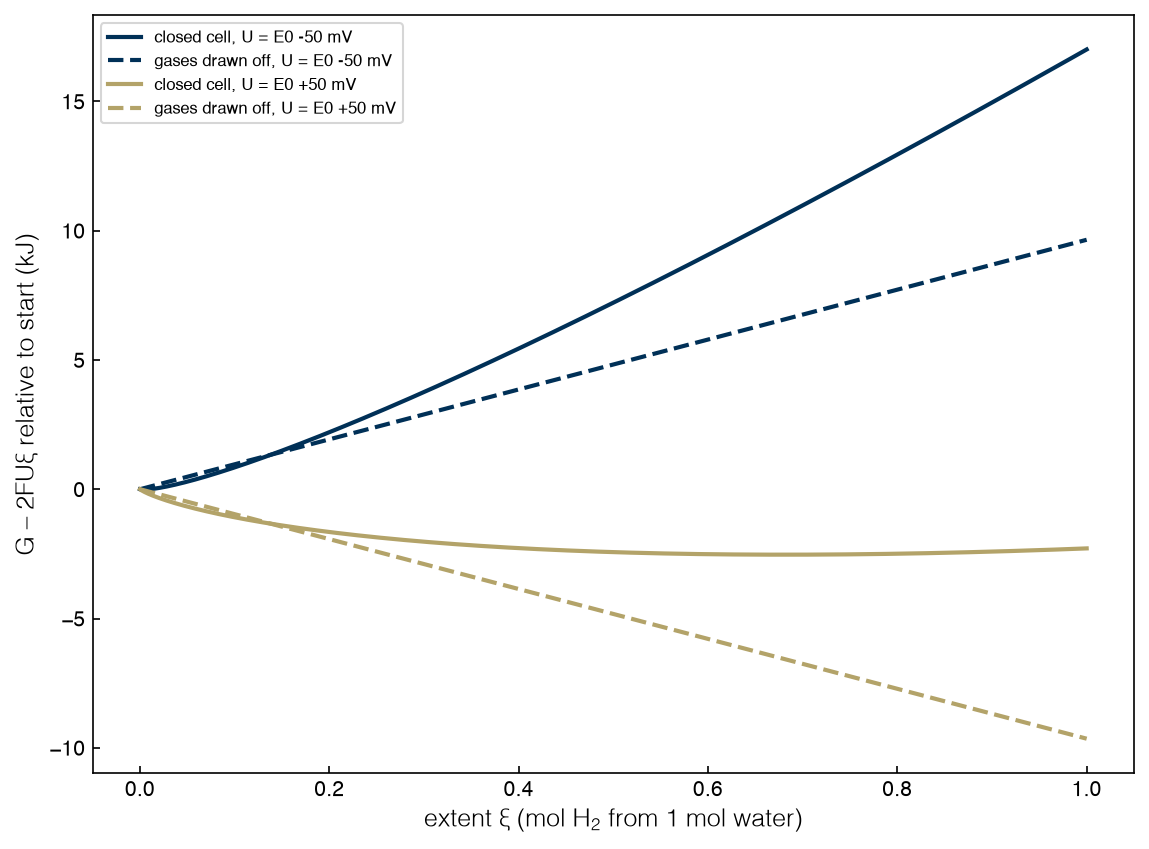

In [4]:
xi = np.linspace(1e-6, 1, 1000)
fig, ax = plt.subplots()
for U, color in ((E0 - 0.05, 'C0'), (E0 + 0.05, 'C3')):
    gc = (g_closed(xi, U) - g_closed(1e-6, U)) / 1e3
    go = (g_open(xi, U) - g_open(0, U)) / 1e3
    ax.plot(xi, gc, color=color, label=f'closed cell, U = E0 {1e3*(U-E0):+.0f} mV')
    ax.plot(xi, go, color=color, ls='--', label=f'gases drawn off, U = E0 {1e3*(U-E0):+.0f} mV')
ax.set_xlabel(r'extent $\xi$ (mol H$_2$ from 1 mol water)')
ax.set_ylabel(r'$G - 2FU\xi$ relative to start (kJ)')
ax.legend(fontsize=8);

As an **alternative formulation**, we could keep all four variables and the three balance constraints and hand the problem to a general constrained solver, which would give the same answer. This approach has one advantage for Topic 2.2, because the solver then reports a number for each constraint, called its multiplier, that tells us how the optimum changes when the constraint is relaxed. For this problem those numbers turn out to be the chemical potentials of the elements and the price of an electron, where the price of the electron is exactly $-FU$.

For the **problem type**, this is an NLP. Since the objective is convex in $\xi$ (the entropy term $\xi \ln \xi$ curves upward), a local method will find the global minimum, so here we can use `minimize_scalar`, which does a bounded one-dimensional search.

The NLP example in the lecture is a different kind of problem, where the goal is to fit the unknown parameters of a semi-empirical equation of state to pressure, volume and temperature measurements. In that case the equation-of-state parameters are the decision variables, the measured data are the fixed parameters of the optimization, and the objective is a measure of the misfit (e.g. the sum of squared or absolute errors). An absolute-value objective can be made linear with extra variables and constraints (Topic 1.4 shows the trick). However, the equation of state itself is still nonlinear in its parameters, so the problem remains an NLP (and a non-convex one). Remember that a problem is linear only if *every* function in it is linear. Local NLP solvers such as Ipopt or sequential quadratic programming (SQP) will find a local fit, while global solvers such as BARON or ANTIGONE can prove which fit is the best one, at a higher cost.


:::{exercise}
:label: ex-t12-headspace

Repeat the closed-cell calculation at $U = E^0 + 50$ mV for headspace volumes of 0.1 L, 1 L and 10 L. How does the amount of hydrogen at equilibrium change, and does the hydrogen partial pressure change? Explain the result using the Nernst equation.
:::

## A MILP: which stacks to switch on

For the **problem definition**, we return to the electrolyzer plant of Topic 1.1, where three stacks must together make 240 kg/h of hydrogen. There are two costs to running a stack: an energy cost that is proportional to its load, and a fixed cost just for having it switched on (pumps, heating, and the power electronics that idle whether or not much hydrogen is made). Which stacks should run, and at what loads?

The **variables** are the loads $x_A, x_B, x_C$ (continuous, between 0 and 1) and three on/off decisions $y_A, y_B, y_C$ (binary).

The **parameters** are the energy cost per unit of load $e_i$ and the fixed cost $F_i$ for each stack, in per-unit power, as well as the demand $D = 1.2$.

| Stack | $e_i$ (per unit of load) | $F_i$ (when on) |
|---|---|---|
| A | 1.20 | 0.30 |
| B | 1.45 | 0.40 |
| C | 1.70 | 0.20 |

The **objective** is to minimize $\sum_i (F_i y_i + e_i x_i)$.

The **constraints** are to meet the demand, and to make sure that a stack has to be switched on before it can carry any load:

$$
\sum_i x_i = D, \qquad x_i \le y_i, \qquad y_i \in \{0, 1\}, \qquad 0 \le x_i .
$$

Notice that the constraint $x_i \le y_i$ does two jobs at once. If $y_i = 0$ the constraint forces $x_i = 0$, and for $y_i = 1$ we get $x_i \le 1$, which is the capacity of the stack. Constraints of this kind, which switch other constraints on and off, are the most common building block in mixed-integer models.

Putting this together, the **formulation** has a linear objective, linear constraints, and some binary variables, so this is a mixed-integer linear program, and `scipy.optimize.milp` can solve it:

In [5]:
e = np.array([el.E_LINEAR[c] for c in el.NAMES])
Fc = np.array([el.F_FIXED[c] for c in el.NAMES])
D = 1.2
# variables: x_A, x_B, x_C, y_A, y_B, y_C
c = np.concatenate([e, Fc])
demand = LinearConstraint(np.r_[np.ones(3), np.zeros(3)], D, D)
link = LinearConstraint(np.hstack([np.eye(3), -np.eye(3)]), -np.inf, 0)   # x_i - y_i <= 0
res = milp(c, constraints=[demand, link], integrality=np.r_[np.zeros(3), np.ones(3)],
           bounds=Bounds(np.zeros(6), np.ones(6)))
x, y = res.x[:3], np.round(res.x[3:])
on = [n for n, yi in zip(el.NAMES, y) if yi > 0.5]
print(f"switch on {' + '.join(on)}; loads {np.round(x, 3)} -> {el.to_kg_h(x).round(0)} kg/h")
print(f"total power {res.fun:.3f} per-unit = {el.to_mw(res.fun):.2f} MW")

switch on A + C; loads [1.  0.  0.2] -> [200.   0.  40.] kg/h
total power 2.040 per-unit = 13.33 MW


The answer is not the one you might guess. Stack A is the most efficient, so it makes sense that it runs at full load. Stack B is the second most efficient per kilogram, but stack C gets switched on instead, since C has a lower fixed cost and only 40 kg/h of extra hydrogen is needed. When the leftover work is small, the fixed cost matters more than the energy cost.

As an **alternative formulation**, we can note that with three stacks there are only $2^3 - 1 = 7$ possible combinations of running stacks. Since the remaining problem is an LP for each choice, we could just solve all seven LPs and keep the best one:

In [6]:
from itertools import product

best = None
for y_try in product((0, 1), repeat=3):
    if sum(y_try) == 0:
        continue
    lp = linprog(e, A_eq=[np.ones(3)], b_eq=[D], bounds=[(0, yi) for yi in y_try])
    if lp.status == 0:
        cost = lp.fun + Fc @ np.array(y_try)
        print(f"on = {y_try}: power {cost:.3f}")
        if best is None or cost < best[0]:
            best = (cost, y_try)
print(f"best: {best[1]} with power {best[0]:.3f}")

on = (0, 1, 1): power 2.390
on = (1, 0, 1): power 2.040
on = (1, 1, 0): power 2.190
on = (1, 1, 1): power 2.390
best: (1, 0, 1) with power 2.040


We can see that the three single-stack choices do not show up, because one stack cannot make 240 kg/h on its own and so those LPs are infeasible. Although enumeration works for this problem, the number of combinations doubles with every additional stack, so for a plant with 30 stacks there would be over a billion combinations. The MILP solver gets the same answer without having to try every combination by using a method called branch-and-bound (developed in Topic 2.5).

For the **problem type**, this is a MILP. Although the binary variables make the problem non-convex, MILPs have a special structure that branch-and-bound solvers can exploit by using LP relaxations as bounds (Topic 2.5). Here `milp` uses HiGHS, and HiGHS proves the answer is globally optimal.

In the lecture, the MILP example chooses warehouse locations, where the goal is to build at most $P$ warehouses out of $N$ candidate sites and ship to $M$ customers at the least cost. It uses the same two devices as the stack model. A binary $y_n$ is equal to 1 if site $n$ is built, and a **linking constraint** blocks shipments from site $n$ unless $y_n = 1$ (e.g. $\sum_m x_{nm} \le U\, y_n$ with $U$ the most that site could ever ship). There is also a **cardinality constraint** $\sum_n y_n \le P$ to limit the number of sites, and demand constraints $\sum_n x_{nm} \ge d_m$ to complete the model. MILPs of this kind can be solved to global optimality with HiGHS, CBC, or the commercial solvers CPLEX and Gurobi.


:::{exercise}
:label: ex-t12-demand-sweep

Solve the stack-selection MILP for demands from 0.2 to 2.8 in steps of 0.2 (40 to 560 kg/h) and record which stacks are switched on. At which demands does the best combination change? Check one of them by enumeration.
:::

## Summary

| Example | Variables | Objective and constraints | Class | Where the answer sits |
|---|---|---|---|---|
| Electrolysis, gases drawn off | continuous | linear | LP | a vertex: all or nothing |
| Electrolysis, closed cell | continuous | nonlinear objective | NLP (convex) | the interior: Nernst |
| Which stacks to switch on | continuous + binary | linear | MILP | a combination of on/off decisions |

- The same recipe (problem, variables, parameters, objective, constraints, formulation, alternatives, class and solver) works for every class.
- Changing one modeling assumption can change the class. Drawing the gases off at fixed pressure made the chemistry linear; sealing the cell made it nonlinear.
- Equivalent formulations can look very different. Eliminating variables, or enumerating integer choices, are useful checks, but they rarely scale.
- In the next topic we will write the same kinds of models in Pyomo, a modeling language that separates the formulation from the solver.

## Additional Reading

- A. J. Bard and L. R. Faulkner, *Electrochemical Methods: Fundamentals and Applications*, 2nd ed., Wiley (2001). Chapter 2 derives the Nernst equation and the link between cell potential and Gibbs energy.
- W. E. Hart, C. D. Laird, J.-P. Watson, D. L. Woodruff, G. A. Hackebeil, B. L. Nicholson and J. D. Siirola, *Pyomo — Optimization Modeling in Python*, 2nd ed., Springer (2017). Used from Topic 1.3 on.
- A. Ravindran, K. M. Ragsdell and G. V. Reklaitis, *Engineering Optimization: Methods and Applications*, 2nd ed., Wiley (2006).
- The SciPy documentation for `scipy.optimize.linprog`, `minimize_scalar` and `milp` (https://docs.scipy.org/doc/scipy/reference/optimize.html).